# 1 Creating and manipulating tensors in pytorch

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt

In [4]:
#testing, where the tensor computation are performed
if torch.cuda.is_available():
    print(torch.cuda.current_device())
    print(torch.cuda.get_device_name(0))
else :
    print('No cuda available')

0
NVIDIA GeForce RTX 4060 Laptop GPU


In [3]:
#vectors as 1d tensors
x = [1,2,3]
y = np.array([4,5,6], dtype=np.int32)
a = torch.tensor(x)
b = torch.from_numpy(y)
print(a)
print(b)

tensor([1, 2, 3])
tensor([4, 5, 6], dtype=torch.int32)


In [4]:
#create a tensor of ones
einsen = torch.ones(5,6)
print(einsen.shape)
print(einsen)

torch.Size([5, 6])
tensor([[1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.]])


In [5]:
#random numbers
r = torch.rand(3,2)
r

tensor([[0.7244, 0.7757],
        [0.7006, 0.8200],
        [0.0070, 0.2242]])

### Manipulating shape and data type

In [6]:
print(b.dtype)
b_new = a.to(torch.int64)
print(b_new.dtype)

torch.int32
torch.int64


In [7]:
#transposing a tensor
r_t = torch.transpose(r, 0, 1)
print(r.shape, 'swapped to', r_t.shape) 
print(r)

torch.Size([3, 2]) swapped to torch.Size([2, 3])
tensor([[0.7244, 0.7757],
        [0.7006, 0.8200],
        [0.0070, 0.2242]])


In [11]:
#Reshaping from a 1d vector to a 2d matrix
t = torch.rand(30)
t_new = t.reshape(6,5)
print(t_new.shape)
print(t_new)

torch.Size([6, 5])
tensor([[0.4328, 0.2381, 0.9260, 0.1888, 0.4447],
        [0.7684, 0.9204, 0.7207, 0.5963, 0.6469],
        [0.9691, 0.5629, 0.3461, 0.4419, 0.3267],
        [0.1318, 0.3947, 0.6885, 0.8705, 0.4301],
        [0.6570, 0.7799, 0.5391, 0.7069, 0.0448],
        [0.3721, 0.0730, 0.2758, 0.8473, 0.5798]])


In [9]:
#Removing unnecessary dimensions
t = torch.ones(1,4,1,6,1,1)
t_new = torch.squeeze(t,2)
print(t.shape, 'squeezed to ', t_new.shape)

torch.Size([1, 4, 1, 6, 1, 1]) squeezed to  torch.Size([1, 4, 6, 1, 1])


### Mathematical functions applied to tensors

In [10]:
#two random tensors of equal shaoe
u = torch.rand(5,2) 
v = torch.normal(mean = 0, std = 1, size=(5,2))

In [11]:
#addition
y = u + v

print("u", u)
print("v", v)
print("y", y)

u tensor([[0.6063, 0.1835],
        [0.2058, 0.2397],
        [0.1687, 0.0284],
        [0.9872, 0.3504],
        [0.0466, 0.3849]])
v tensor([[-0.0018,  0.1709],
        [-0.3248,  1.5758],
        [ 1.1015, -1.4619],
        [-1.3776,  1.2191],
        [ 0.9618,  0.0819]])
y tensor([[ 0.6045,  0.3544],
        [-0.1190,  1.8155],
        [ 1.2702, -1.4335],
        [-0.3904,  1.5695],
        [ 1.0084,  0.4668]])


#### In place operations

In [12]:
#in place
x1 = torch.rand(2, 3)
x2 = torch.rand(2, 3)
print("X1 (before)", x1)
print("X2 (before)", x2)

x2.add_(x1)
print("X1 (after)", x1)
print("X2 (after)", x2)



X1 (before) tensor([[0.7432, 0.0849, 0.2433],
        [0.3819, 0.4695, 0.8407]])
X2 (before) tensor([[0.0228, 0.0795, 0.9539],
        [0.1973, 0.6654, 0.4693]])
X1 (after) tensor([[0.7432, 0.0849, 0.2433],
        [0.3819, 0.4695, 0.8407]])
X2 (after) tensor([[0.7659, 0.1644, 1.1972],
        [0.5792, 1.1349, 1.3101]])


#### Further functions

In [13]:
#elementwise multiplication
w = torch.multiply(u,v)
print(w)

tensor([[-1.0908e-03,  3.1355e-02],
        [-6.6844e-02,  3.7776e-01],
        [ 1.8585e-01, -4.1525e-02],
        [-1.3601e+00,  4.2719e-01],
        [ 4.4838e-02,  3.1536e-02]])


In [14]:
#compute the mean of the columns and rows
print(torch.mean(w,axis=0))
print(torch.mean(w,axis=1))

tensor([-0.2395,  0.1653])
tensor([ 0.0151,  0.1555,  0.0722, -0.4664,  0.0382])


In [15]:
# Matrix multiplication
x = torch.matmul(u, torch.transpose(v,0,1))
print(x)

tensor([[ 0.0303,  0.0922,  0.3996, -0.6115,  0.5981],
        [ 0.0406,  0.3109, -0.1238,  0.0087,  0.2176],
        [ 0.0046, -0.0100,  0.1443, -0.1978,  0.1646],
        [ 0.0581,  0.2315,  0.5752, -0.9329,  0.9783],
        [ 0.0657,  0.5913, -0.5113,  0.4050,  0.0764]])


In [16]:
# Matrix multiplication again
y = torch.matmul(torch.transpose(u, 0, 1), v)
print(y)

tensor([[-1.1973,  1.3887],
        [-0.1595,  0.8263]])


In [17]:
# computing the L^2-norm 
z = torch.normal(mean = 0, std = 1, size=(5,1))
norm = torch.linalg.norm(z, ord=2, dim = 0)
print('z',z, '\n ||z||=',norm)

z tensor([[-0.9737],
        [-1.2339],
        [-1.0187],
        [-0.4780],
        [-0.9503]]) 
 ||z||= tensor([2.1541])


In [18]:
# computing the L2-norm for the columns of a vector
norm = torch.linalg.norm(w,ord=2,dim=0)
print('w', w,'\n||w||=',norm)

w tensor([[-1.0908e-03,  3.1355e-02],
        [-6.6844e-02,  3.7776e-01],
        [ 1.8585e-01, -4.1525e-02],
        [-1.3601e+00,  4.2719e-01],
        [ 4.4838e-02,  3.1536e-02]]) 
||w||= tensor([1.3751, 0.5735])


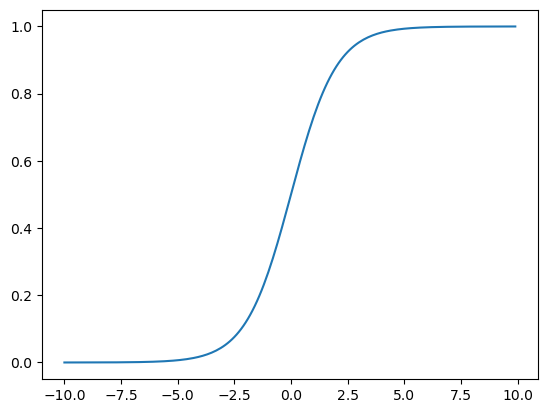

In [19]:
s = torch.arange(-10,10, 0.1)
y = torch.sigmoid(s)
plt.plot(s,y)

### Indexing

In [20]:
x.shape

torch.Size([5, 5])

In [21]:
x[0,0] = -100000

In [22]:
#First column
x[:,0]

tensor([-1.0000e+05,  4.0597e-02,  4.5505e-03,  5.8104e-02,  6.5684e-02])

In [23]:
print(x[:2, -1]) # First two rows, last column

tensor([0.5981, 0.2176])


In [24]:
print(x[1:3, :]) # second and third row

tensor([[ 0.0406,  0.3109, -0.1238,  0.0087,  0.2176],
        [ 0.0046, -0.0100,  0.1443, -0.1978,  0.1646]])


### Splitting, stacking and concatenating

In [25]:
# splittung a vector into 3 chunks
t = torch.rand(8)
print(t)
t_c = torch.chunk(t,3)
print(t_c)
for item in t_c:
    print(item)
    

tensor([0.1137, 0.4875, 0.2556, 0.1336, 0.1773, 0.9892, 0.5027, 0.8929])
(tensor([0.1137, 0.4875, 0.2556]), tensor([0.1336, 0.1773, 0.9892]), tensor([0.5027, 0.8929]))
tensor([0.1137, 0.4875, 0.2556])
tensor([0.1336, 0.1773, 0.9892])
tensor([0.5027, 0.8929])


In [26]:
# splittung into a given size
print(t)
t_c = torch.split(t,split_size_or_sections=[4,2,2])
print(t_c)
for item in t_c:
    print(item)

tensor([0.1137, 0.4875, 0.2556, 0.1336, 0.1773, 0.9892, 0.5027, 0.8929])
(tensor([0.1137, 0.4875, 0.2556, 0.1336]), tensor([0.1773, 0.9892]), tensor([0.5027, 0.8929]))
tensor([0.1137, 0.4875, 0.2556, 0.1336])
tensor([0.1773, 0.9892])
tensor([0.5027, 0.8929])


In [27]:
#concatenating
A = torch.ones(3)
B = -torch.ones(2)
C = torch.cat([A,B],axis =0)
print(C)

tensor([ 1.,  1.,  1., -1., -1.])


In [28]:
#stacking
A = torch.ones(3)
B = -torch.ones(3)
S = torch.stack([A,B], axis=0)
print('S',S)
S2 = torch.stack([A,B], axis=1)
print('S2',S2)

S tensor([[ 1.,  1.,  1.],
        [-1., -1., -1.]])
S2 tensor([[ 1., -1.],
        [ 1., -1.],
        [ 1., -1.]])


### Tensor to Numpy and vice versa

In [29]:
np_arr = np.array([[1, 2], [3, 4]])
tensor = torch.from_numpy(np_arr)

print("Numpy array:", np_arr)
print("PyTorch tensor:", tensor)

Numpy array: [[1 2]
 [3 4]]
PyTorch tensor: tensor([[1, 2],
        [3, 4]])


In [30]:
tensor = torch.arange(4)
np_arr = tensor.numpy()

print("PyTorch tensor:", tensor)
print("Numpy array:", np_arr)

PyTorch tensor: tensor([0, 1, 2, 3])
Numpy array: [0 1 2 3]


The conversion from a pytorch tensor to a numpy array will only work, when the tensor is already on the CPU. 
Otherwise, please call  np_arr = tensor.cpu().numpy() first.

In [31]:
tensor = torch.arange(4)
np_arr = tensor.cpu().numpy()

print("PyTorch tensor:", tensor)
print("Numpy array:", np_arr)

PyTorch tensor: tensor([0, 1, 2, 3])
Numpy array: [0 1 2 3]
